# Zadanie EDA: ceny domów w Ames
Autor: Iga Kaczmarek


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

import os
try:
    from google.colab import files
    if not os.path.exists("train.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("train.csv", keep_default_na=False, na_values=["NA"])
df.shape

(1460, 81)

## Pytania naprowadzające
**Zmienna docelowa:** SalePrice, czyli cena sprzedaży domu w USD.

**Rodzaje zmiennych:** liczbowe (np. GrLivArea, LotArea, YearBuilt) i kategoryczne (np. Neighborhood, BldgType). Tekstowych w sensie dowolnego tekstu nie ma, kolumny tekstowe to kategorie.

## Do zrobienia

Podstawowe statystyki opisowe

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


Typy danych wszystkich kolumn

In [15]:
df.dtypes

,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


Sprawdzenie braków danych

In [16]:
braki = df.isna().sum()
braki[braki > 0].sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageCond,81
GarageType,81
GarageYrBlt,81
GarageFinish,81


Braki w PoolQC, Alley, Fence, MiscFeature, FireplaceQu, Garage... i Bsmt... według data_description.txt oznaczają, że dom nie ma danej cechy (basenu, alejki, garażu, piwnicy itd.), więc to nie są prawdziwe braki. Prawdziwe braki to LotFrontage, MasVnrType/MasVnrArea i Electrical.

Wykresy

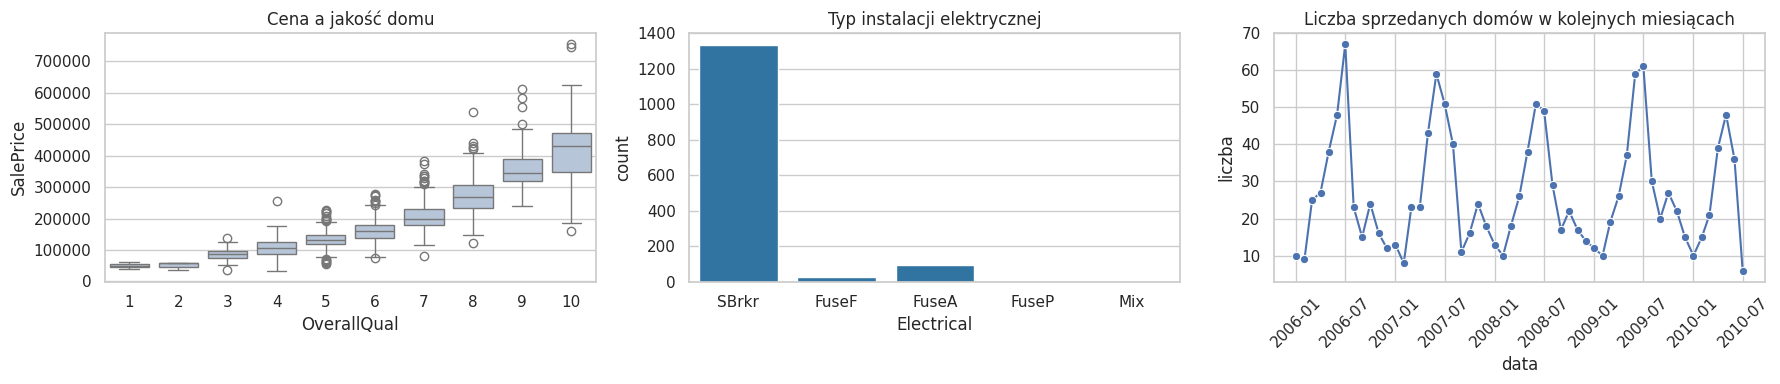

In [17]:
sprzedaz = df.groupby(["YrSold", "MoSold"]).size().reset_index(name="liczba")
sprzedaz["data"] = pd.to_datetime(dict(year=sprzedaz["YrSold"], month=sprzedaz["MoSold"], day=1))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[0], color="lightsteelblue")
axes[0].set_title("Cena a jakość domu")

sns.countplot(data=df, x="Electrical", ax=axes[1], color="tab:blue")
axes[1].set_title("Typ instalacji elektrycznej")

sns.lineplot(data=sprzedaz, x="data", y="liczba", marker="o", ax=axes[2])
axes[2].set_title("Liczba sprzedanych domów w kolejnych miesiącach")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Cena rośnie wraz z jakością domu.

## Analiza zmiennej docelowej

Histogram

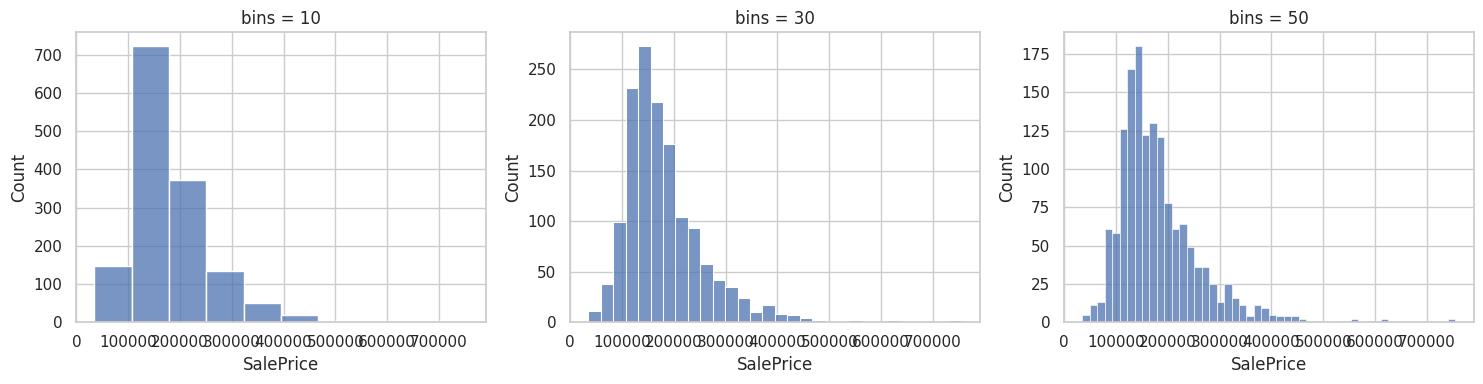

In [18]:
p = df["SalePrice"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, b in zip(axes, [10, 30, 50]):
    sns.histplot(p, bins=b, ax=ax)
    ax.set_title(f"bins = {b}")
plt.tight_layout()
plt.show()

Wykres pudełkowy

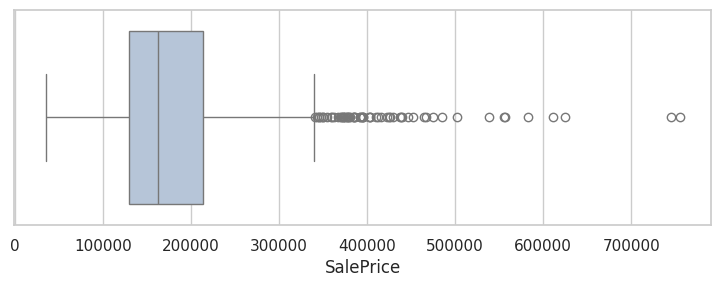

In [19]:
plt.figure(figsize=(9, 2.8))
sns.boxplot(x=p, color="lightsteelblue")
plt.show()

Policzone: min, max, średnią, medianę, 𝑄1, 𝑄3,
IQR

In [20]:
q1, q3 = p.quantile([0.25, 0.75])
iqr = q3 - q1
print("min    :", p.min())
print("max    :", p.max())
print("średnia:", round(p.mean()))
print("mediana:", p.median())
print("Q1     :", q1)
print("Q3     :", q3)
print("IQR    :", iqr)
print("domów powyżej Q3 + 1.5*IQR:", (p > q3 + 1.5 * iqr).sum())

min    : 34900
max    : 755000
średnia: 180921
mediana: 163000.0
Q1     : 129975.0
Q3     : 214000.0
IQR    : 84025.0
domów powyżej Q3 + 1.5*IQR: 61


- **Rozkład cen:** prawostronnie skośny, większość domów jest tania lub średnia, a nieliczne bardzo drogie. Zmiana liczby przedziałów nie zmienia tego kształtu.
- **Wartości odstające:** są, 61 domów powyżej górnego płotu, a poniżej dolnego żadnych. To pewnie duże domy wysokiej jakości, więc nie muszą być błędami.
- **Średnia i mediana:** średnia 180 921 USD, mediana 163 000 USD. Średnia jest większa, bo ciągną ją drogie domy.
- **Czy rozkład jest normalny:** nie, histogram nie jest symetryczny.

## Co wpływa na cenę domu?

Hipoteza: *większe domy są droższe*.

Zmienne związane z powierzchnią


In [21]:
kol_pow = [c for c in df.columns if "Area" in c or "SF" in c]
print(kol_pow)

['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']


Wykres punktowy


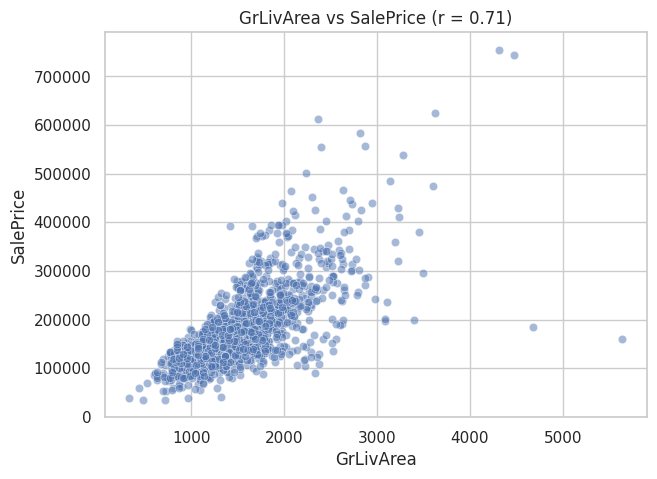

In [22]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.5)
plt.title(f"GrLivArea vs SalePrice (r = {df['GrLivArea'].corr(df['SalePrice']):.2f})")
plt.show()

In [23]:
df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]]

,Id,GrLivArea,SalePrice,OverallQual,SaleCondition
523,524,4676,184750,10,Partial
691,692,4316,755000,10,Normal
1182,1183,4476,745000,10,Abnorml
1298,1299,5642,160000,10,Partial


Zależność jest wyraźna i mniej więcej liniowa: większy dom to zwykle wyższa cena.

Dziwne obserwacje to dwa największe domy (Id 524 i 1299), które mają ocenę jakości 10, ale kosztowały tylko 185 tys. i 160 tys. USD. Oba to sprzedaże częściowe (SaleCondition = Partial), czyli domy nie były ukończone i cena nie odzwierciedla ich wartości.

Dodatkowo

▪ Czy powierzchnia działki (LotArea) ma taki sam wpływ jak powierzchnia domu?

Wykresy punktowe:

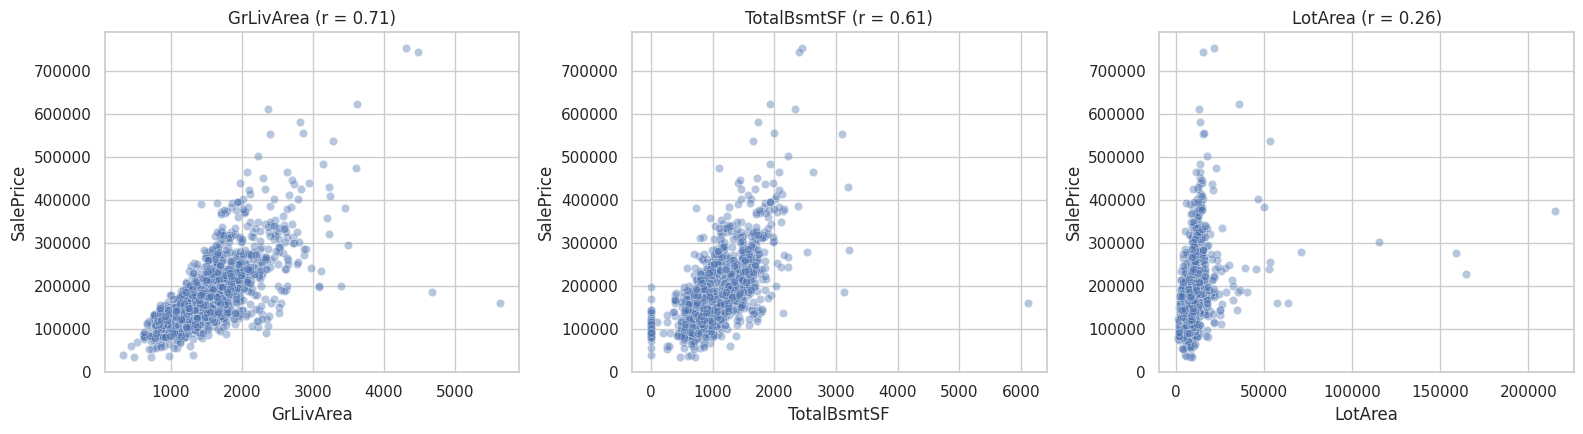

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c in zip(axes, ["GrLivArea", "TotalBsmtSF", "LotArea"]):
    sns.scatterplot(data=df, x=c, y="SalePrice", alpha=0.4, ax=ax)
    ax.set_title(f"{c} (r = {df[c].corr(df['SalePrice']):.2f})")
plt.tight_layout()
plt.show()

Najsilniejszy związek z ceną ma GrLivArea (0,71), potem TotalBsmtSF (0,61). Powierzchnia działki LotArea (0,26) wpływa na cenę dużo słabiej niż powierzchnia domu, bo są bardzo duże działki o przeciętnych cenach.